# Real pairs: do rules and frozen scores pick better seeds than random sets?

`first_look.py` ran six real pairs over the weekend (7–8 Nov). Sections 1–6 read those original results. Sections 7–11 add saved synthetic-selector transfer, solver diagnostics, broader candidate sets, new Enron windows and separate real-topology controls. The new collection cells are opt-in and resumable; opening/running the notebook with their flags left False reads saved results only.

**Pairs.** All unweighted and undirected; A is the graph seeds are chosen from.
- **Worm (hermaphrodite):** C. elegans chemical (A) vs gap-junction (B) synapses, all 279 neurons, and the 247 neurons in the largest component of both graphs.
- **Worm (male):** the same for the male connectome, 167 neurons.
- **Enron:** e-mail in week 130 (A) vs week 131 or 132 (B), the largest component of both weeks.
- **Wikipedia:** English (A) vs French (B) articles, 1,382.

**Design.** 20% of each pair's vertices are test vertices, never seeds, and B's labels are shuffled once. At each budget:
- 30 random sets (15 for Wikipedia) from a pool of 1,000;
- round 1's six rules;
- the best set of the pool by each graph model's frozen score (ER, Chung–Lu, PAPER weights) and by degree.

**Variants.** Percolation, FAQ (3 runs per set; 1 for Wikipedia), and GOAT with regulariser 100 (ER's value) and 300 (Chung–Lu's and PAPER's).

**Caveat.** Test sets are small (28–56 vertices except Wikipedia's 276) and each rule is a single set per budget, so differences of a few points are within noise. Look for gains that hold across budgets and pairs.

In [1]:
import os
import sys
import tempfile
from pathlib import Path

os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'sgm_matplotlib_cache'))

import importlib

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / 'experiment_common').is_dir())
if ROOT.name == 'real_data_experiments':
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from real_data_experiments import first_look as F
F = importlib.reload(F)   # picks up edits to first_look.py without restarting the kernel

pd.set_option('display.max_rows', 300)
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 250)

## 1. The pairs

How much the two graphs of a pair overlap limits every method: the worm's chemical and gap-junction graphs share only about 10% of the chemical edges (edge correlation 0.17), the Enron weeks and Wikipedia far more. **Degree CV** is the spread of A's degrees (ER at mean degree 8 is about 0.35; Chung–Lu and PAPER are heavier-tailed).

In [2]:
per = F.per_set()
display(F.pair_table())

,vertices,test vertices,edges in A,edges in B,mean degree A,mean degree B,degree CV of A,isolated in B,edge correlation,share of A's edges in B,budgets
pair,,,,,,,,,,,
"Worm (hermaphrodite), all 279",279,56,1961,514,14.1,3.7,0.80,26,0.167,0.096,"25, 50, 100, 150, 200"
"Worm, common largest component (247)",247,49,1617,508,13.1,4.1,0.84,0,0.182,0.115,"25, 50, 100, 150"
"Worm (male), 167",167,33,1690,913,20.2,10.9,0.62,2,0.365,0.309,"10, 20, 40, 60, 80"
"Enron, weeks 130 vs 131 (145)",145,29,377,363,5.2,5.0,1.38,0,0.891,0.878,"5, 10, 20, 40, 60"
"Enron, weeks 130 vs 132 (141)",141,28,372,360,5.3,5.1,1.37,0,0.765,0.761,"5, 10, 20, 40, 60"
"Wikipedia, English vs French (1,382)",1382,276,18857,14973,27.3,21.7,1.30,59,0.464,0.422,"10, 20, 30, 50, 75"


## 2. Accuracy against seeds

One panel per pair: random sets' mean (grey line) and 10th–90th percentile (grey band), and five choices of seeds: the distinguishing and hub-free distinguishing rules, top degree, the best of 1,000 random sets by the ER score, and clustered seeds (the pair-mass rule). Change `methods=` to show others (names in `F.METHODS`).

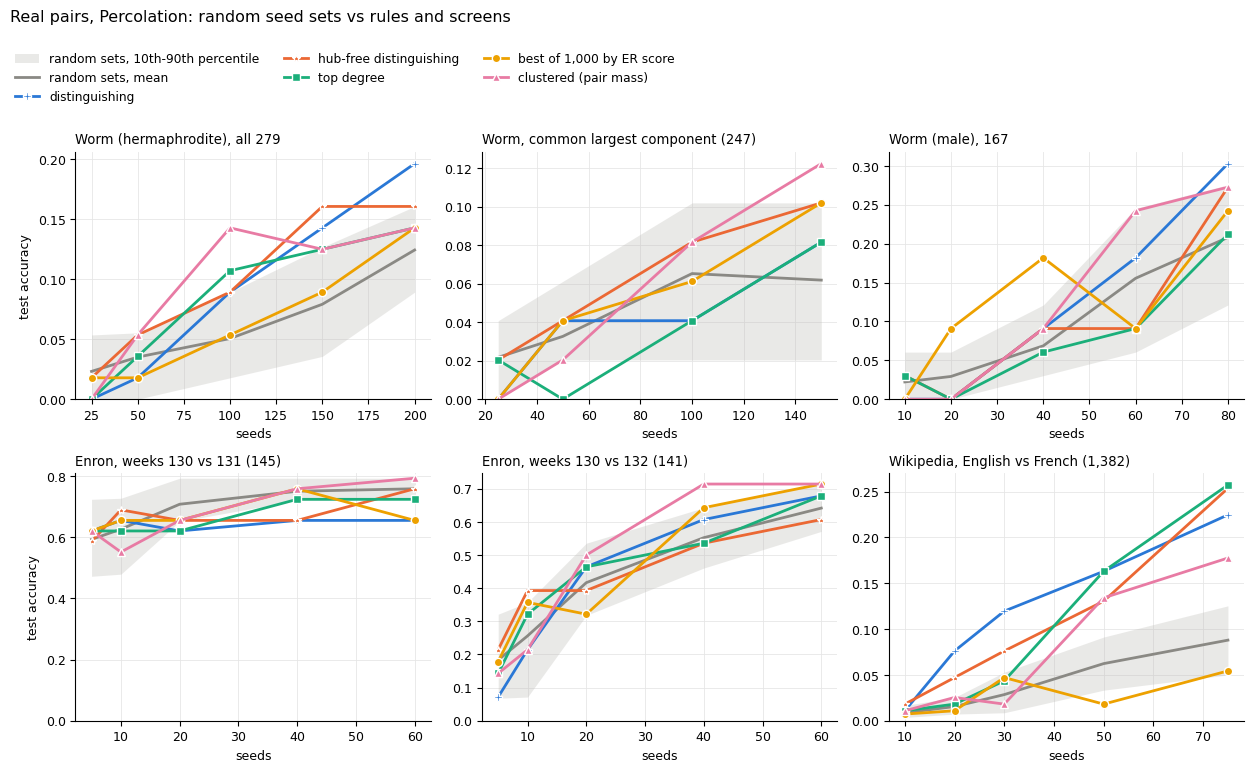

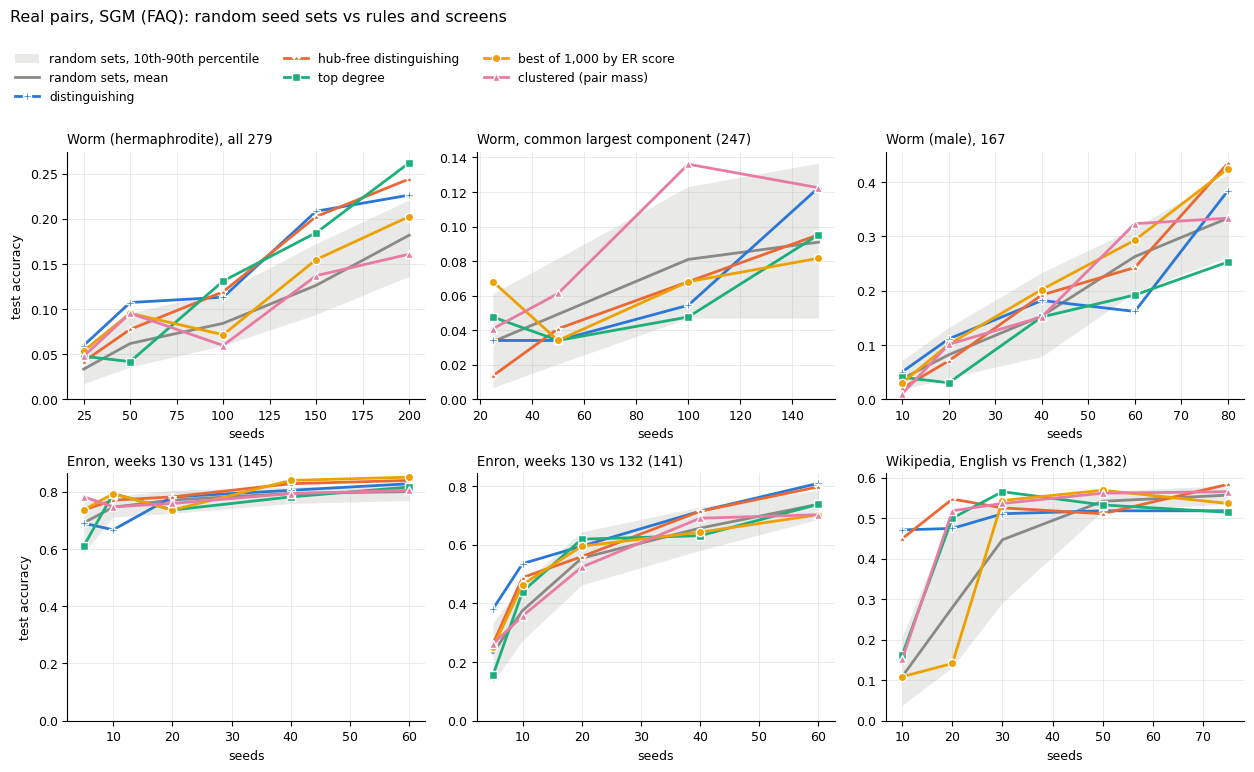

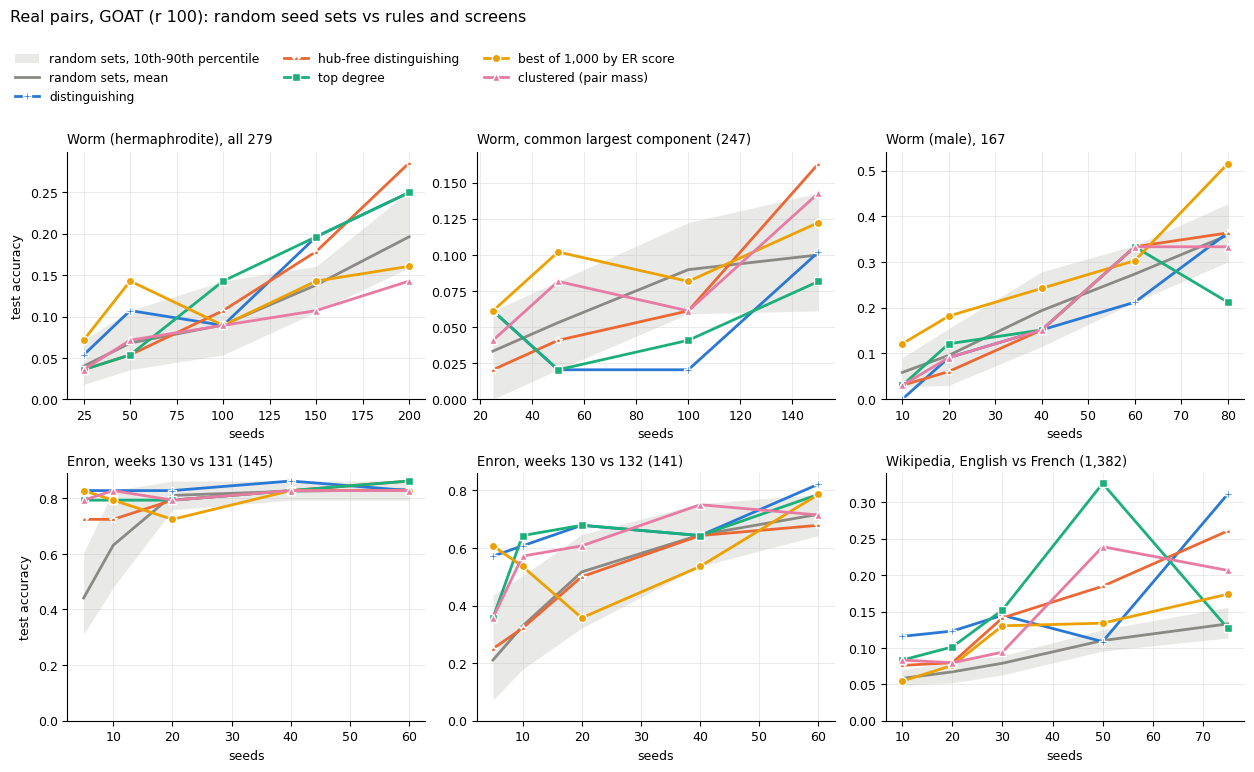

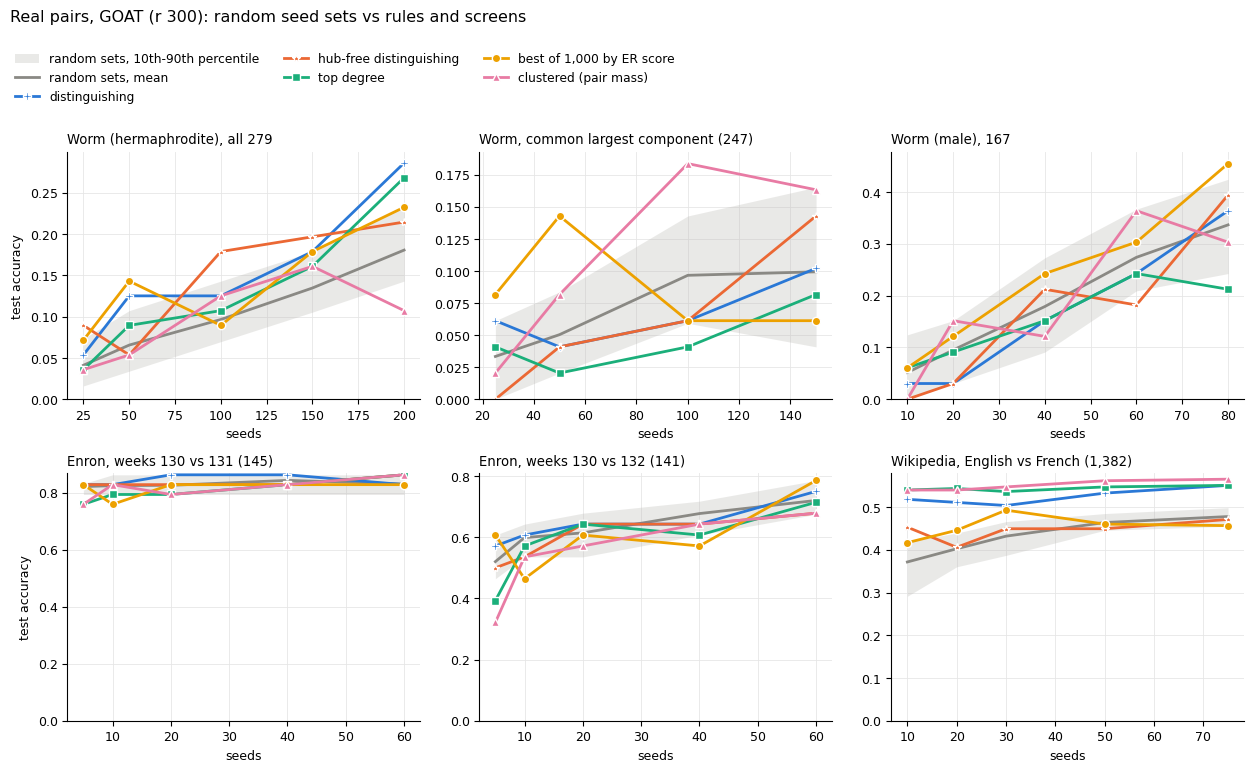

In [16]:
for variant in F.VARIANTS:
    F.plot_budgets(per, variant)
    plt.show()

### The numbers (FAQ)

Random sets' mean, SD, 10th and 90th percentiles and best set (of 30), then every rule and screen. Set `variant` to `'goat_r100'`, `'goat_r300'` or `'percolation'` for the others.

In [4]:
variant = 'faq'
display(F.budget_table(per, variant))

random mean  random SD  random 10th pct  random 90th pct  best random set  random sets  top degree  top harmonic  clustered (pair mass)  spread (coverage)  distinguishing  hub-free distinguishing  \
pair                                 budget                                                                                                                                                                                                        
Worm (hermaphrodite), all 279        25            0.033      0.016            0.017            0.054            0.065           30       0.048         0.054                  0.048              0.042           0.060                    0.042   
                                     50            0.062      0.023            0.036            0.096            0.119           30       0.042         0.065                  0.095              0.048           0.107                    0.077   
                                     100           0.084      0.024            0.060            0.119            0.131           30       0.131         0.137                  0.060              0.101           0.113                    0.119   
                                     150           0.126      0.032            0.094            0.173            0.202           30       0.185         0.143                  0.137              0.143           0.208                    0.202   
                                     200           0.182      0.038            0.136            0.221            0.262           30       0.262         0.190                  0.161              0.238           0.226                    0.244   
Worm, common largest component (247) 25            0.033      0.020            0.007            0.061            0.068           30       0.048         0.020                  0.041              0.020           0.034                    0.014   
                                     50            0.049      0.022            0.020            0.082            0.095           30       0.034         0.061                  0.061              0.027           0.034                    0.041   
                                     100           0.081      0.030            0.047            0.123            0.150           30       0.048         0.095                  0.136              0.054           0.054                    0.068   
                                     150           0.091      0.032            0.047            0.137            0.156           30       0.095         0.095                  0.122              0.122           0.122                    0.095   
Worm (male), 167                     10            0.038      0.025            0.018            0.072            0.091           30       0.040         0.040                  0.010              0.010           0.051                    0.020   
                                     20            0.082      0.040            0.039            0.132            0.172           30       0.030         0.010                  0.101              0.101           0.111                    0.071   
                                     40            0.153      0.058            0.079            0.233            0.273           30       0.152         0.152                  0.152              0.182           0.182                    0.192   
                                     60            0.263      0.057            0.197            0.315            0.364           30       0.192         0.323                  0.323              0.414           0.162                    0.242   
                                     80            0.333      0.063            0.262            0.414            0.444           30       0.253         0.374                  0.333              0.222           0.384                    0.434   
Enron, weeks 130 vs 131 (145)        5             0.691      0.067            0.585            0.770            0.816           30       0.6

## 3. Gains over random sets

Each rule's and screen's test accuracy minus the random sets' mean at the same pair, variant and budget, averaged over budgets. **Share above random** counts the (pair, budget) cases where the method beat the random mean.

In [5]:
display(F.gain_table(per))

pair                                          Worm (hermaphrodite), all 279  Worm, common largest component (247)  Worm (male), 167  Enron, weeks 130 vs 131 (145)  Enron, weeks 130 vs 132 (141)  Wikipedia, English vs French (1,382)  all pairs  \
variant      method                                                                                                                                                                                                                                  
Percolation  top degree                                               0.020                                -0.010            -0.018                         -0.025                          0.019                                 0.058      0.008   
             top harmonic                                            -0.002                                 0.006            -0.012                         -0.032                         -0.046                                 0.071     -0.003   
             clustered (pair mass)                                    0.030                                 0.011             0.024                         -0.011                          0.047                                 0.033      0.023   
             spread (coverage)                                        0.020                                -0.010            -0.018                         -0.039                          0.076                                 0.073      0.018   
             distinguishing                                           0.027                                -0.005             0.018                         -0.046                         -0.003                                 0.078      0.012   
             hub-free distinguishing                                  0.034                                 0.016             0.000                         -0.018                          0.019                                 0.064      0.019   
             best of 1,000 by ER score                                0.002                                 0.006             0.024                         -0.018                          0.033                                -0.013      0.006   
             best of 1,000 by Chung-Lu score                         -0.016                                -0.005             0.012                         -0.094                         -0.003                                -0.001     -0.018   
             best of 1,000 by PAPER score                            -0.016                                -0.005             0.024                         -0.094                          0.004                                -0.001     -0.015   
             best of 1,000 by degree                                 -0.009                                -0.015             0.006                          0.023                          0.040                                -0.001      0.008   
SGM (FAQ)    top degree                                               0.036                                -0.007            -0.040                         -0.013                          0.005                                 0.068      0.009   
             top harmonic                                             0.020                                 0.004             0.006                         -0.020                         -0.009                                 0.066      0.012   
             clustered (pair mass)                                    0.003                                 0.027             0.010                          0.017                         -0.004                                 0.080      0.022   
             spread (coverage)                                        0.017                                -0.007             0.012                          0.015                          0.024                                 0.104      0.029   
             distinguishing                                     

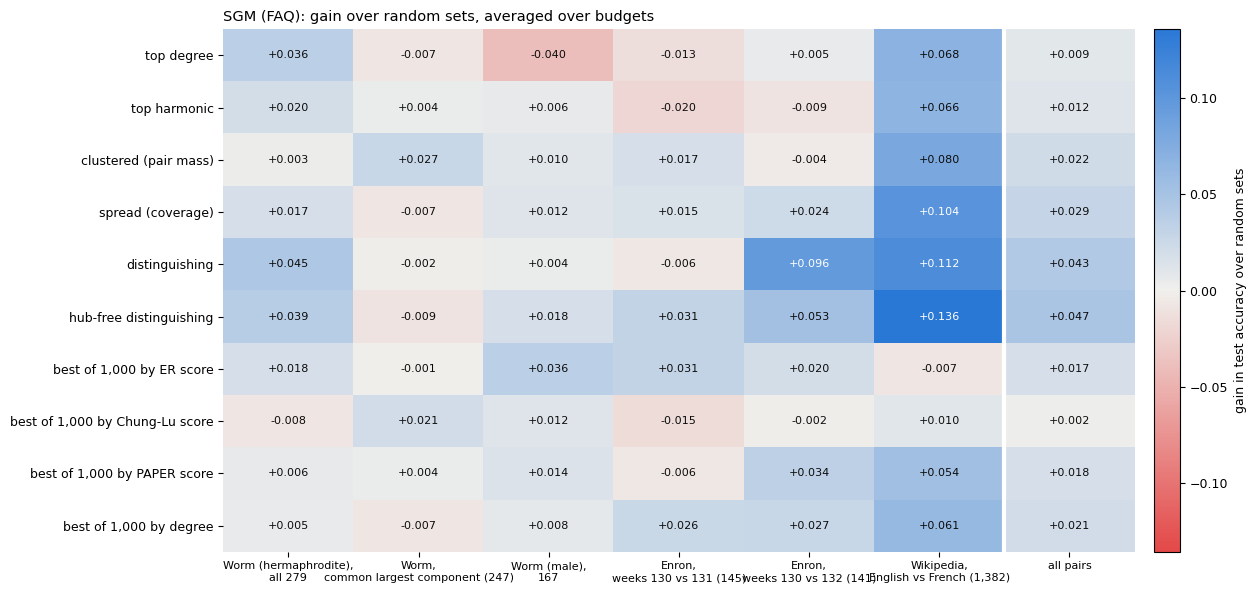

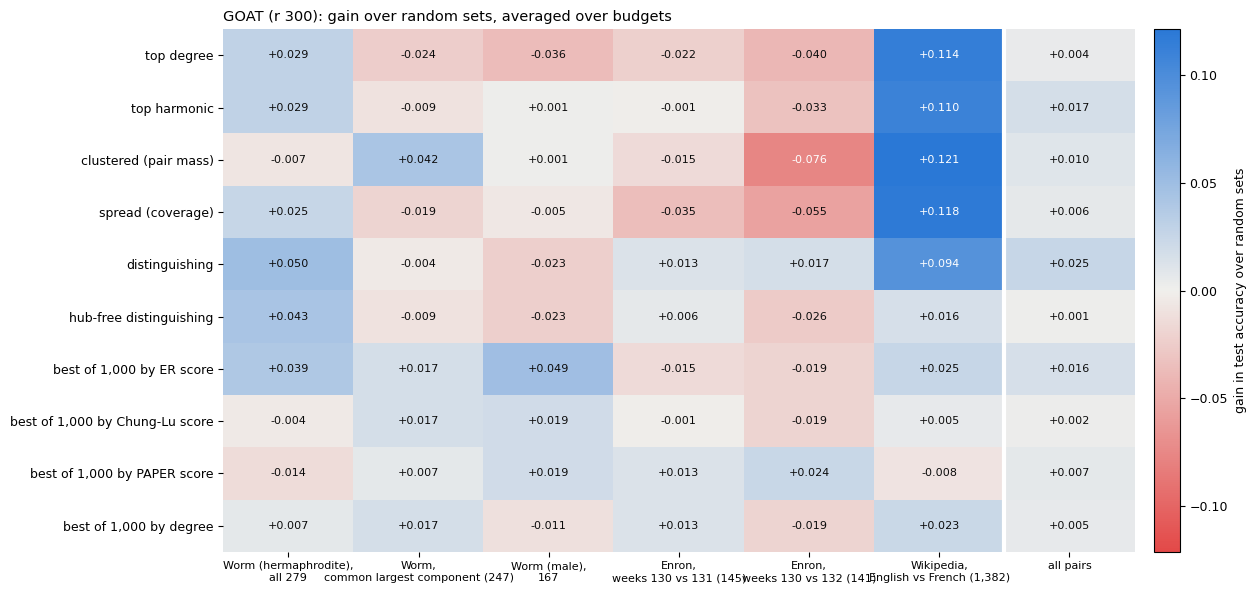

In [6]:
for variant in ('faq', 'goat_r300'):
    F.plot_gain_heatmap(per, variant)
    plt.show()

## 4. Weighted score vs performance on real pairs

Rows are pairs and columns budgets. Grey: the random sets; orange and dark shapes: round 1's rules; blues and aqua: the screens. The title gives the Spearman correlation between the score and accuracy over the random sets. Change `score` to `'score_cl'`, `'score_paper'` or `'z_degree'`.

With 30 random sets and small test sets, a single panel's correlation is noisy; the table after the figures averages it over budgets.

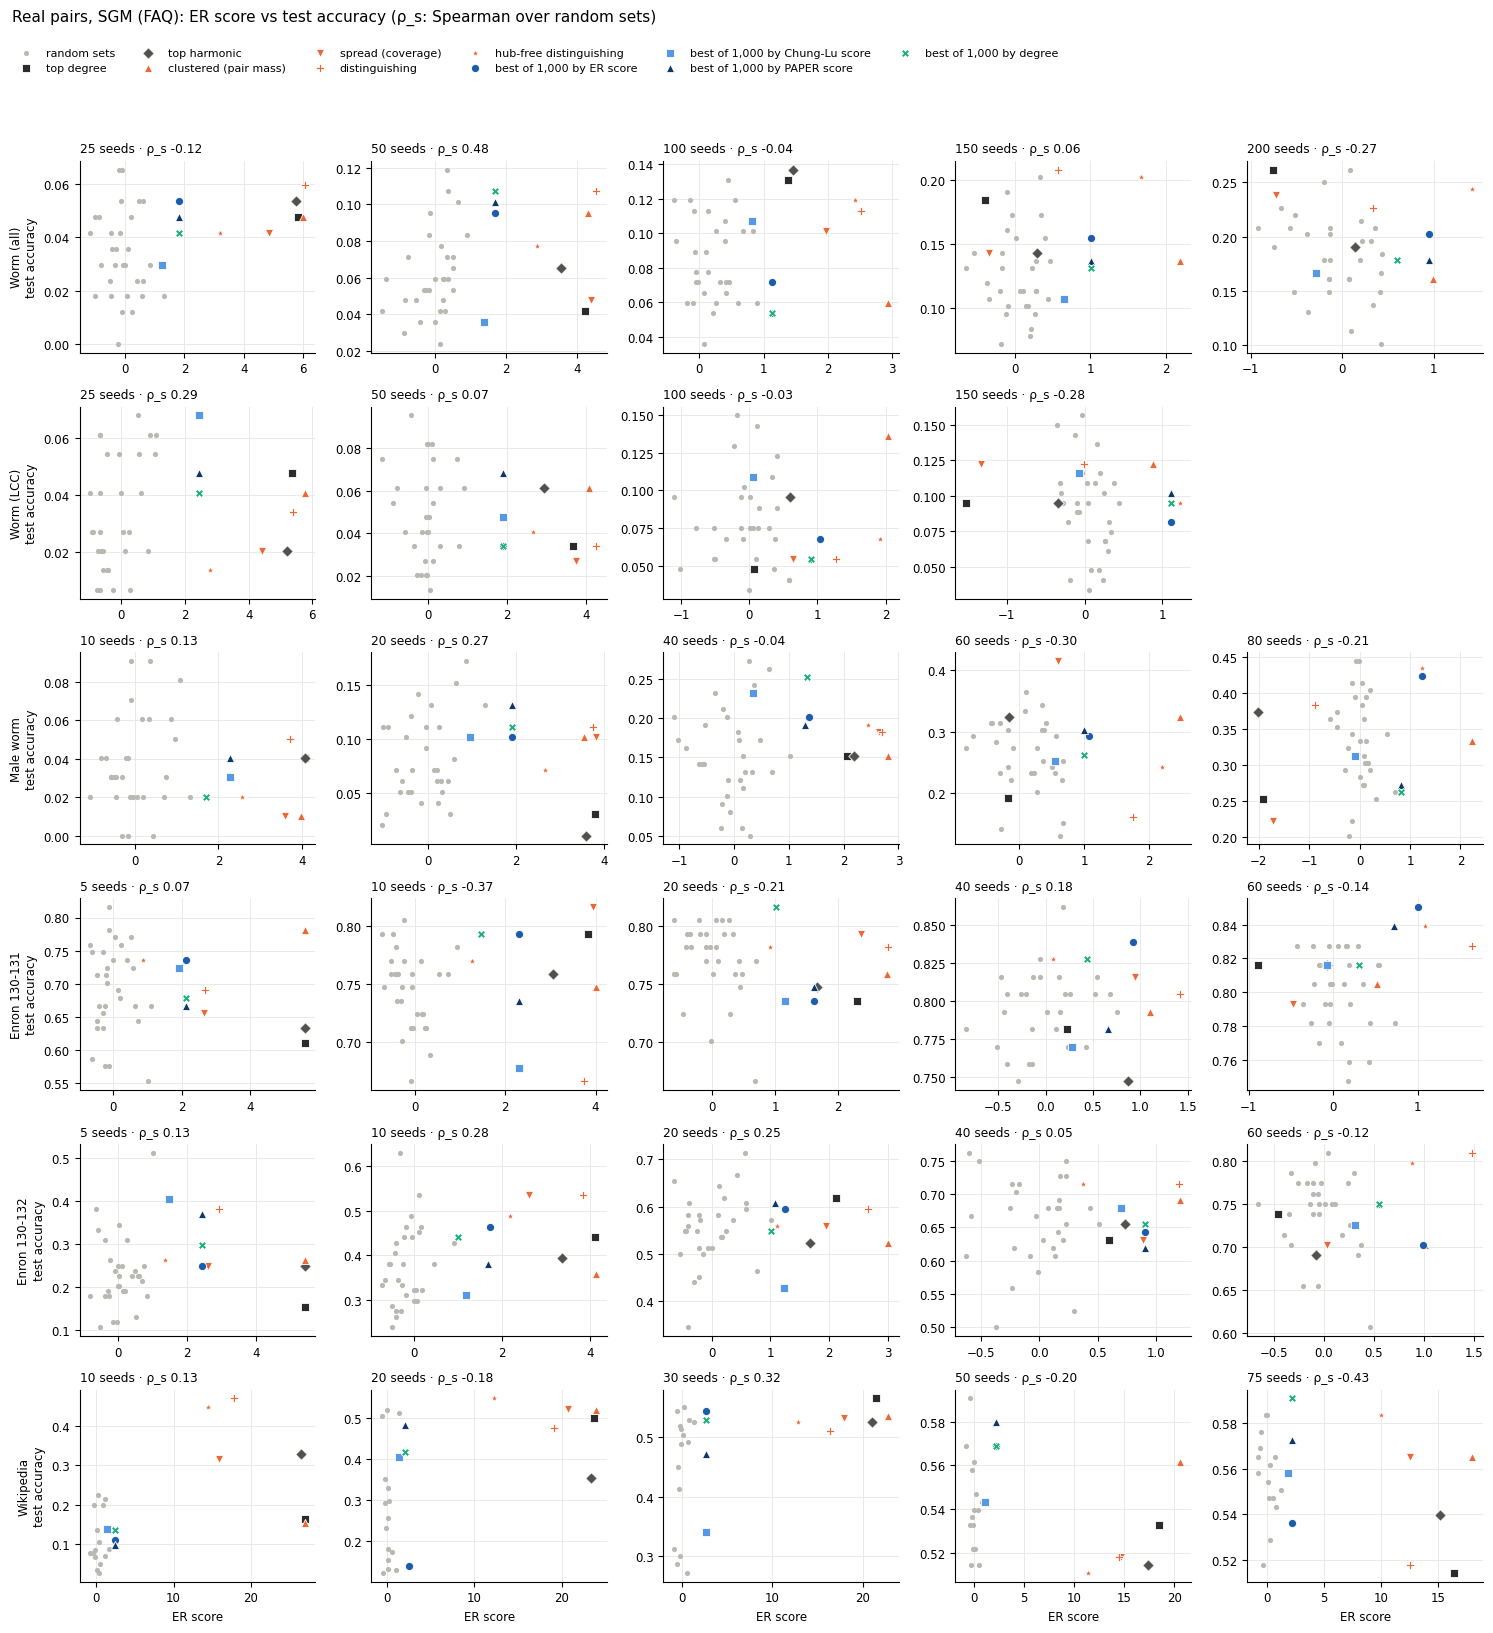

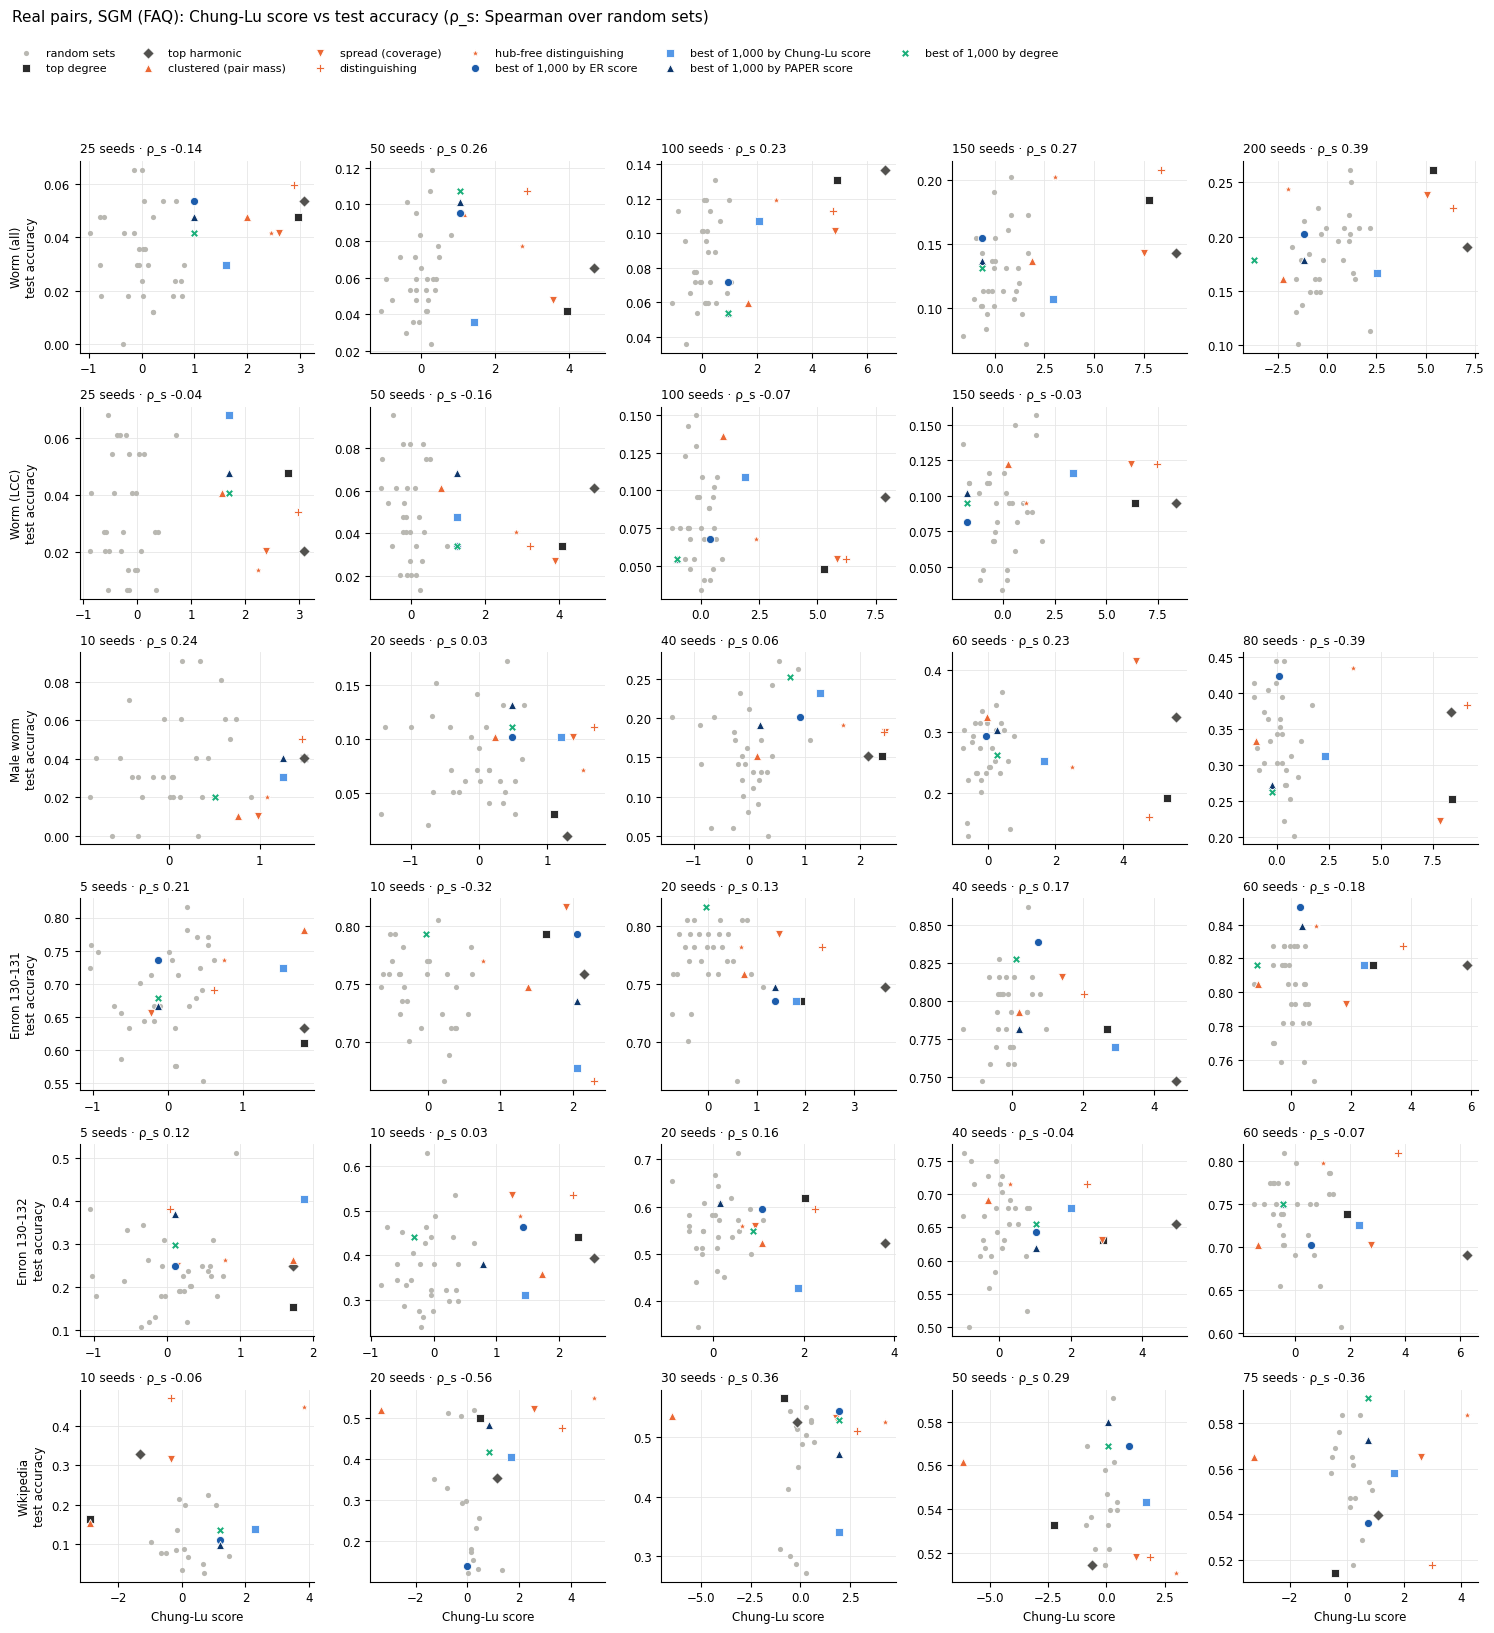

In [7]:
for score in ('score_er', 'score_cl'):
    F.plot_scores(per, 'faq', score)
    plt.show()

In [8]:
display(F.score_table(per))

ER score  Chung-Lu score  PAPER score  degree (z)
pair                                 variant                                                        
Worm (hermaphrodite), all 279        Percolation      -0.04            0.03         0.04       -0.02
                                     SGM (FAQ)         0.02            0.20        -0.10       -0.11
                                     GOAT (r 100)      0.13            0.10         0.11        0.00
                                     GOAT (r 300)      0.10            0.16         0.12       -0.16
Worm, common largest component (247) Percolation      -0.12            0.02        -0.02       -0.19
                                     SGM (FAQ)         0.01           -0.08         0.03        0.05
                                     GOAT (r 100)     -0.10           -0.10        -0.07        0.01
                                     GOAT (r 300)     -0.09            0.01         0.05       -0.11
Worm (male), 167                     Percolation      -0.05            0.01         0.01       -0.05
                                     SGM (FAQ)        -0.03            0.03         0.01       -0.02
                                     GOAT (r 100)     -0.10            0.01         0.00       -0.03
                                     GOAT (r 300)     -0.14           -0.05        -0.04       -0.04
Enron, weeks 130 vs 131 (145)        Percolation      -0.01           -0.02        -0.03       -0.01
                                     SGM (FAQ)        -0.09            0.00        -0.04       -0.02
                                     GOAT (r 100)      0.08           -0.10        -0.03        0.21
                                     GOAT (r 300)     -0.02           -0.08        -0.04        0.08
Enron, weeks 130 vs 132 (141)        Percolation      -0.07           -0.09        -0.10        0.07
                                     SGM (FAQ)         0.12            0.04         0.20        0.21
                                     GOAT (r 100)      0.03           -0.33        -0.15        0.33
                                     GOAT (r 300)     -0.17           -0.19        -0.09        0.05
Wikipedia, English vs French (1,382) Percolation       0.02            0.10         0.06       -0.02
                                     SGM (FAQ)        -0.07           -0.07         0.01       -0.00
                                     GOAT (r 100)     -0.12            0.03         0.08       -0.15
                                     GOAT (r 300)      0.09           -0.09        -0.04        0.04

## 5. The four solver variants

Random sets' mean test accuracy for each variant. GOAT's regulariser matters a lot on some pairs (Wikipedia, Enron), so a fixed value is not safe on real graphs.

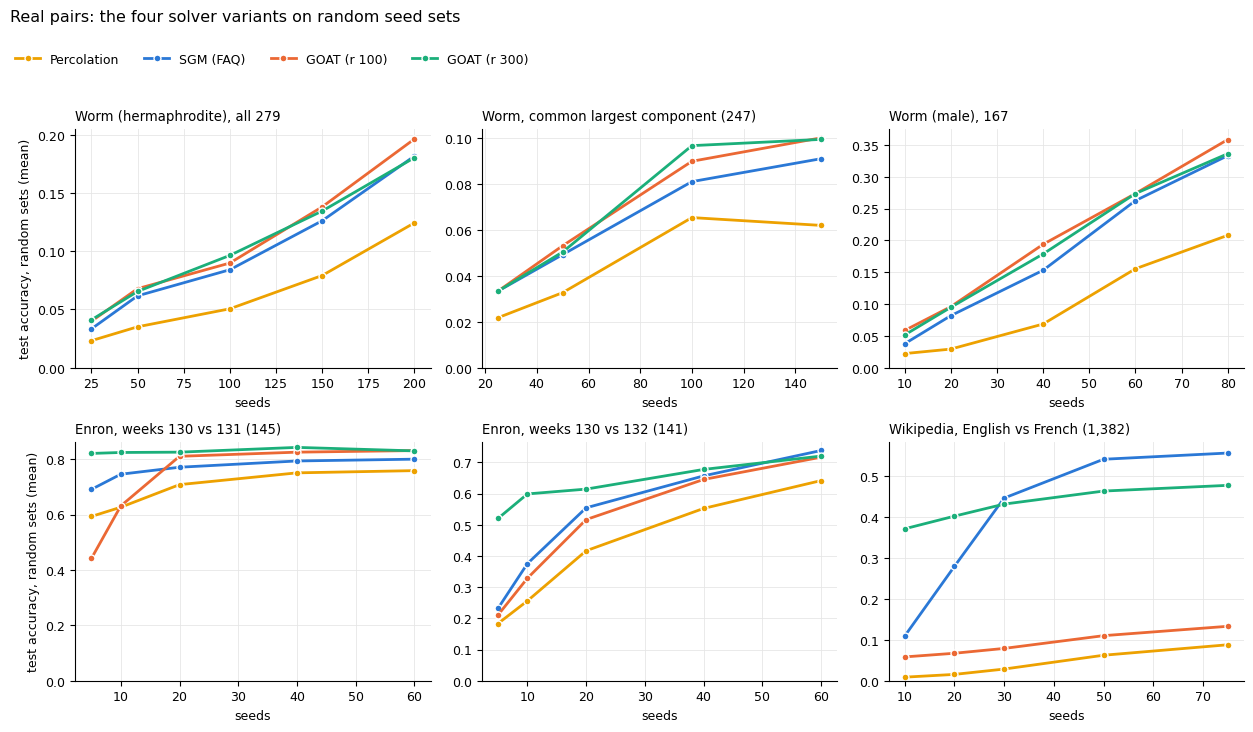

variant                                      Percolation  SGM (FAQ)  GOAT (r 100)  GOAT (r 300)
pair                                 budget                                                    
Worm (hermaphrodite), all 279        25            0.023      0.033         0.040         0.041
                                     50            0.035      0.062         0.068         0.065
                                     100           0.051      0.084         0.090         0.096
                                     150           0.079      0.126         0.138         0.135
                                     200           0.124      0.182         0.196         0.180
Worm, common largest component (247) 25            0.022      0.033         0.033         0.033
                                     50            0.033      0.049         0.053         0.050
                                     100           0.065      0.081         0.090         0.097
                                     150           0.062      0.091         0.100         0.099
Worm (male), 167                     10            0.022      0.038         0.059         0.052
                                     20            0.029      0.082         0.096         0.095
                                     40            0.069      0.153         0.194         0.179
                                     60            0.156      0.263         0.274         0.274
                                     80            0.208      0.333         0.359         0.336
Enron, weeks 130 vs 131 (145)        5             0.593      0.691         0.441         0.821
                                     10            0.626      0.746         0.631         0.824
                                     20            0.708      0.771         0.810         0.825
                                     40            0.751      0.793         0.825         0.843
                                     60            0.759      0.800         0.831         0.830
Enron, weeks 130 vs 132 (141)        5             0.183      0.232         0.211         0.520
                                     10            0.256      0.375         0.329         0.599
                                     20            0.417      0.554         0.517         0.614
                                     40            0.552      0.657         0.645         0.677
                                     60            0.642      0.738         0.717         0.720
Wikipedia, English vs French (1,382) 10            0.009      0.109         0.058         0.371
                                     20            0.015      0.279         0.067         0.402
                                     30            0.029      0.447         0.079         0.432
                                     50            0.062      0.542         0.110         0.464
                                     75            0.088      0.557         0.133         0.478

In [9]:
F.plot_variants(per)
plt.show()
display(F.variant_table(per))

## 6. The worm by neuron class (FAQ)

**Same class:** the share of test neurons matched to a neuron of the same class (motor, interneuron, sensory). A random matching would get `same_class_chance()`, about 0.36. Even where exact accuracy is low (3–26%), about half the test neurons land on a neuron of the right class.

In [10]:
print(f"Same class by chance: {F.same_class_chance('worm'):.3f}")
display(F.class_table(per, 'worm', 'faq'))
display(F.class_breakdown(per, 'worm', 'faq'))

Same class by chance: 0.359


test accuracy                             same class                            
budget                                    25     50     100    150    200        25     50     100    150    200
random sets (mean)                      0.033  0.062  0.084  0.126  0.182      0.461  0.503  0.505  0.513  0.526
top degree                              0.048  0.042  0.131  0.185  0.262      0.435  0.440  0.571  0.542  0.607
top harmonic                            0.054  0.065  0.137  0.143  0.190      0.446  0.530  0.512  0.536  0.577
clustered (pair mass)                   0.048  0.095  0.060  0.137  0.161      0.476  0.446  0.452  0.542  0.577
spread (coverage)                       0.042  0.048  0.101  0.143  0.238      0.429  0.470  0.530  0.560  0.565
distinguishing                          0.060  0.107  0.113  0.208  0.226      0.518  0.446  0.577  0.595  0.565
hub-free distinguishing                 0.042  0.077  0.119  0.202  0.244      0.476  0.476  0.482  0.571  0.542
best of 1,000 by ER score               0.054  0.095  0.071  0.155  0.202      0.452  0.464  0.506  0.494  0.506
best of 1,000 by Chung-Lu score         0.030  0.036  0.107  0.107  0.167      0.369  0.494  0.548  0.560  0.560
best of 1,000 by PAPER score            0.048  0.101  0.054  0.137  0.179      0.476  0.512  0.536  0.518  0.524
best of 1,000 by degree                 0.042  0.107  0.054  0.131  0.179      0.440  0.476  0.560  0.506  0.470

,motor,interneuron,sensory,all test neurons
random sets (mean),0.096,0.102,0.095,0.097
top degree,0.105,0.204,0.111,0.133
top harmonic,0.095,0.160,0.116,0.118
clustered (pair mass),0.097,0.133,0.071,0.100
spread (coverage),0.077,0.191,0.102,0.114
distinguishing,0.126,0.196,0.120,0.143
hub-free distinguishing,0.162,0.084,0.147,0.137
"best of 1,000 by ER score",0.115,0.142,0.089,0.115
"best of 1,000 by Chung-Lu score",0.087,0.107,0.076,0.089
"best of 1,000 by PAPER score",0.097,0.142,0.076,0.104


## Reading the first-look results

- **The worm is hard for the tested methods.** At 200 seeds, FAQ's random mean is 18.2% and top degree gets 26.2%. These are observed accuracies, not a proven ceiling imposed by edge overlap. The common-component case remains hard, so isolates alone do not explain the difficulty.
- **Rule-built sets show promising gains at small budgets.** On Wikipedia, distinguishing reaches 47.1% at 10 seeds against 10.9% random. On Enron 130–132, distinguishing and spread reach 53.6% at 10 seeds against 37.5% random. Each is still one natural pair and one test split.
- **Frozen-score transfer is mixed.** Random-set correlations are generally weak or inconsistent, but screening sometimes helps: Wikipedia at 20 seeds gets 48.2% with the PAPER-score screen and 14.1% with the ER-score screen, against 27.9% random. This tests pools of 1,000, not an impossibility of screening or construction with these scores. Section 9 broadens the candidate range.
- **Solver settings matter.** GOAT's regularizer changes the random baseline substantially. Many FAQ runs on Enron 130–131 hit 100 iterations. Section 8 checks iteration sensitivity and records numerical warnings; a returned matching is not necessarily a converged optimum.
- **Replication is conditional on each natural pair.** Random seed sets, repeated solver runs, B relabelings and test splits do not create new natural graph pairs. The overlapping worm cases and Enron weeks should not be treated as independent datasets.

## 7. Transfer of the saved synthetic selectors

First score the **existing** candidate sets with saved final models from `learned_selector`. Nothing is fitted to real outcomes. All nine source settings are evaluated for FAQ and percolation. GOAT uses compatible source regularizers: three ER models at r=100, or six Chung–Lu/PAPER models at r=300. The source manifest records every source setting and model hash.

The fixed transfer policy takes the **equal-weight mean prediction** of the compatible models, then picks the candidate with the largest mean prediction. We do not select the source model by its real test accuracy. This is reranking a shared candidate bank, not a claim of globally optimizing a learned score. Individual-source checks are available for the expanded bank in section 9.

Both columns below show the **same evaluated sets and outcomes**: frozen ER score on the left, synthetic-model mean predicted accuracy on the right. The dashed y=x line applies only to predicted accuracy. These are out-of-training-domain predictions; feature-range coverage is reported separately, and high predicted accuracy may be poorly calibrated. Original outcomes retain their original precision: three FAQ runs per set on small pairs, one on Wikipedia; no B averaging.

candidate_sets  source_models  mean_share_in_source_ranges
case          variant                                                                
enron_130_131 faq                     200              9                        0.986
              goat_r100               200              3                        0.685
              goat_r300               200              6                        0.770
              percolation             200              9                        0.615
enron_130_132 faq                     200              9                        0.985
              goat_r100               200              3                        0.692
              goat_r300               200              6                        0.767
              percolation             200              9                        0.599
wikipedia     faq                     125              9                        0.756
              goat_r100               125              3                        0.517
              goat_r300               125              6                        0.607
              percolation             125              9                        0.495
worm          faq                     200              9                        0.947
              goat_r100               200              3                        0.657
              goat_r300               200              6                        0.737
              percolation             200              9                        0.554
worm_lcc      faq                     160              9                        0.956
              goat_r100               160              3                        0.690
              goat_r300               160              6                        0.754
              percolation             160              9                        0.588
worm_male     faq                     200              9                        0.973
              goat_r100               200              3                        0.807
              goat_r300               200              6                        0.855
              percolation             200              9                        0.761

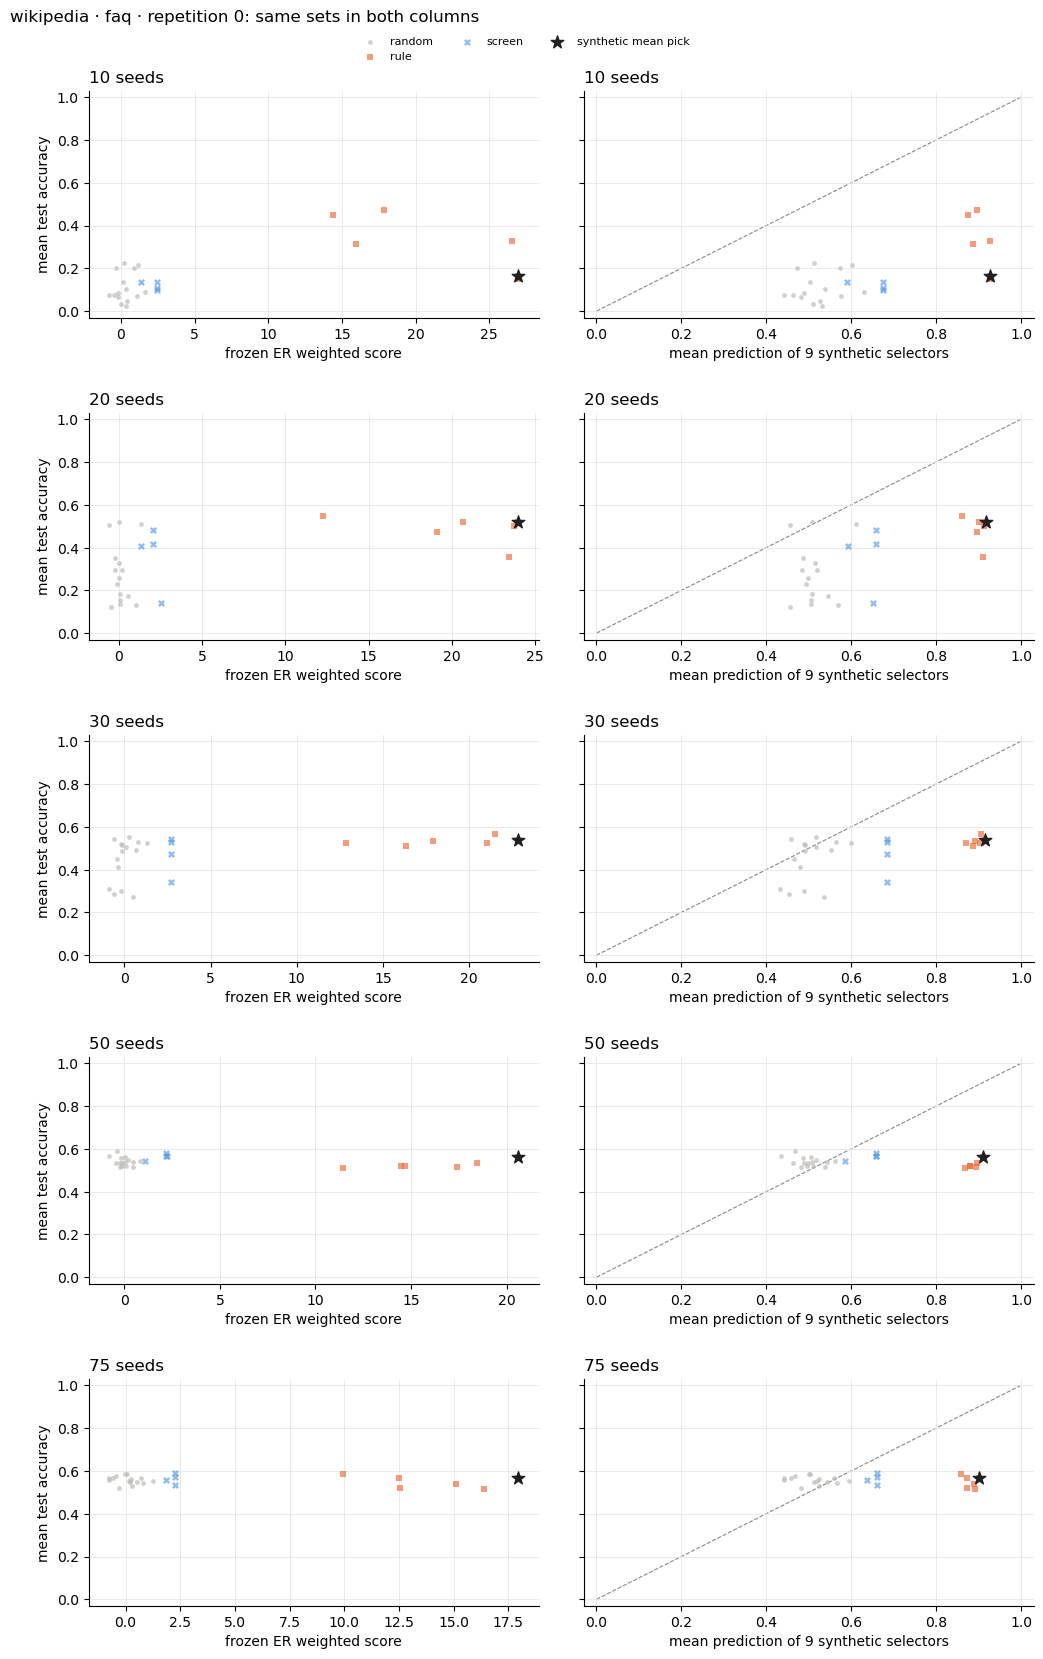

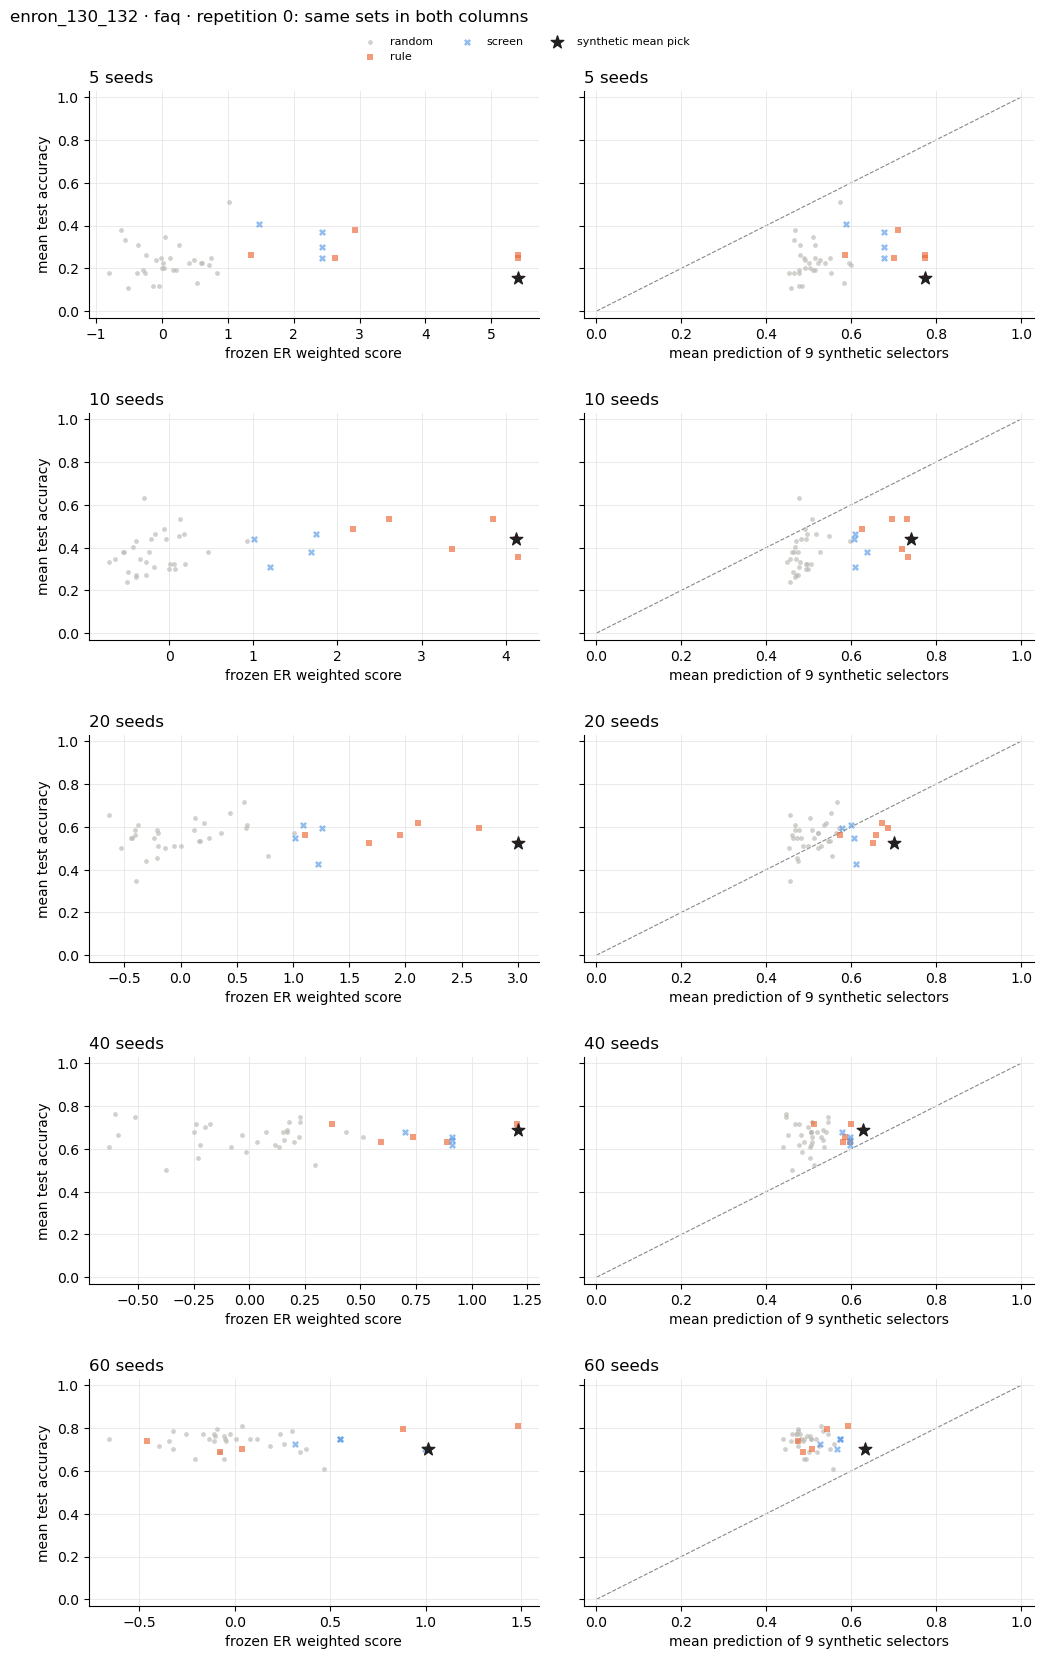

In [11]:
from real_data_experiments import broader_candidates as U
U = importlib.reload(U)
FOLLOW_UP_FIGURES = U.OUTPUT_DIR / "figures"
FOLLOW_UP_FIGURES.mkdir(parents=True, exist_ok=True)

existing_scored, existing_members = U.score_existing()
display(existing_scored.groupby(["case", "variant"]).agg(
    candidate_sets=("candidate_id", "size"), source_models=("source_count", "first"),
    mean_share_in_source_ranges=("source_range_share", "mean")).round(3))
for case in ("wikipedia", "enron_130_132"):
    fig = U.plot_scores(existing_scored, existing_members, case, "faq")
    for suffix in ("png", "pdf"):
        fig.savefig(FOLLOW_UP_FIGURES / f"{case}_existing_selector_transfer.{suffix}", dpi=180)
    plt.show()

## 8. Solver stability before interpreting small seed-selection gains

Compare FAQ at **100 and 500 iterations** with identical candidate sets and solver seeds. Compare GOAT at r=100 and r=300. Each seed set has three solver runs; the same solver seed is used across candidates within a repetition, and identical sets are evaluated once and shared across policy memberships. Numerical warnings are saved in `runs.csv`.

The earlier Enron 100–101/102 window is a **development diagnostic**; Enron 130–131 is an exploratory check of the known iteration-limit issue. These diagnostics do not automatically choose settings by held-out accuracy. The wider tests keep their solver configurations fixed in `settings.json`: FAQ at 100 iterations and GOAT at r=300, with alternatives available explicitly. A 500-iteration result can still fail the convergence criterion; compare stability as well as accuracy.

The initial diagnostic subset has been collected. Set the flag below to extend it to all configured budgets and repetitions. All raw runs remain resumable and separate from `results/first_look`.

In [12]:
RUN_STABILITY_COLLECTION = False
if RUN_STABILITY_COLLECTION:
    U.run("stability", jobs=3)

display(U.collection_status("stability"))
stability_sets, stability_members, stability_predictions = U.read("stability")
if not stability_sets.empty:
    display(U.stability_table(stability_sets))
else:
    print("No follow-up solver diagnostics collected yet.")

,case,variant,budget,replicate,runs,planned
0,enron_100_102,faq,10,0,36,36
1,enron_100_102,faq_500,10,0,36,36
2,enron_100_102,goat_r100,10,0,39,39
3,enron_100_102,goat_r300,10,0,39,39
4,enron_130_131,faq,10,0,33,33
5,enron_130_131,faq_500,10,0,33,33
6,enron_130_131,goat_r100,10,0,39,39
7,enron_130_131,goat_r300,10,0,39,39


accuracy  convergence_share  mean_iterations  warning_count
case          budget variant                                                               
enron_100_102 10     faq           0.551              0.750           36.889              0
                     faq_500       0.553              0.750          136.889              0
                     goat_r100     0.632              1.000           11.538              0
                     goat_r300     0.644              1.000            9.692              0
enron_130_131 10     faq           0.749              0.394           69.727              0
                     faq_500       0.762              0.394          312.152              0
                     goat_r100     0.738              1.000            6.000              0
                     goat_r300     0.809              1.000            8.769              0

## 9. Broader candidate sets and synthetic-selector reranking

At each graph/test-split/budget, use one reference pool of **1,000 uniform sets** to standardize the four core features. The new reference pools are fixed for this follow-up; they do not alter the original first-look pools or results. Add:

- 30 random sets (15 for Wikipedia), the six original rules and four pool screens;
- exact top ten **eligible** fixed-size sets for mean total vertex degree and harmonic centrality;
- ten highest encountered sets for cut degree, pair mass, uniqueness and coverage, and for **each** ER/CL/PAPER frozen score, using multiple starts and sampled single swaps;
- intermediate seed sets on random-to-high-value swap paths, sampled across the frozen ER score range.

Only the additive degree/harmonic groups have global top-ten guarantees, conditional on the eligible vertices. The other groups are the best encountered within the declared search budget. We rank their pooled candidates again for each metric. All selection uses A only; test vertices are excluded. Features and distances still use the full graph.

**Fair score comparison:** the three frozen scores and the synthetic mean each select their best set from exactly the same expanded bank. We also retain each saved source selector's own choice: it ranks candidates inside its original feature-range guard if available, otherwise records an out-of-range choice. The synthetic mean ranks the entire bank; its range coverage is descriptive, not a guarantee against joint extrapolation. No real labels enter the candidate search, source-model choice or model fitting.

The first Enron subset has actual outcomes. Wikipedia's broader A-only plans at k=10,20,30 are saved, but the new matching calls are pending. They can take hours; section 7 already provides transfer plots using its existing outcomes. The flags below leave long collections opt-in. `--plan-only` creates reviewable candidates and predictions without matching.

,case,variant,budget,replicate,runs,planned
0,enron_130_132,faq,10,0,423,423
1,enron_130_132,faq,10,1,417,417
2,enron_145_147,faq,10,0,426,426
3,enron_145_147,faq,10,1,435,435
4,enron_160_162,faq,10,0,426,426
5,enron_160_162,faq,10,1,438,438
6,wikipedia,faq,10,0,0,231
7,wikipedia,faq,20,0,0,300
8,wikipedia,faq,30,0,0,339


detail                              best of 1,000 by Chung-Lu score  best of 1,000 by degree  best of 1,000 by ER score  best of 1,000 by PAPER score  clustered (pair mass)  distinguishing  CL score: expanded bank  ER score: expanded bank  \
phase case          variant budget                                                                                                                                                                                                               
wide  enron_130_132 faq     10                                0.357                    0.470                      0.339                         0.345                  0.375           0.357                    0.298                    0.446   
      enron_145_147 faq     10                                0.198                    0.302                      0.310                         0.349                  0.294           0.294                    0.190                    0.238   
      enron_160_162 faq     10                                0.263                    0.439                      0.404                         0.377                  0.281           0.360                    0.360                    0.368   

detail                              PAPER score: expanded bank  hub-free distinguishing  random mean  spread (coverage)  synthetic selectors: mean prediction  top degree  top harmonic  
phase case          variant budget                                                                                                                                                       
wide  enron_130_132 faq     10                           0.482                    0.470        0.395              0.476                                 0.435       0.405         0.423  
      enron_145_147 faq     10                           0.357                    0.302        0.280              0.381                                 0.310       0.325         0.206  
      enron_160_162 faq     10                           0.439                    0.377        0.299              0.342                                 0.386       0.342         0.377

MAE  Spearman  in_source_range
phase case          variant budget source                                                          
wide  enron_130_132 faq     10     chung_lu/faq/d10_rho0.50/k031   0.257     0.082            1.000
                                   chung_lu/faq/d16_rho0.30/k107   0.064     0.011            0.869
                                   chung_lu/faq/d32_rho0.30/k053   0.117    -0.020            0.894
                                   paper_pa/faq/d08_rho0.50/k022   0.427     0.124            1.000
                                   paper_pa/faq/d16_rho0.30/k053   0.339     0.107            1.000
                                   paper_pa/faq/d32_rho0.30/k048   0.368     0.084            1.000
                                   sparse_er/faq/d08_rho0.50/k058  0.229     0.090            1.000
                                   sparse_er/faq/d16_rho0.30/k143  0.261     0.099            0.475
                                   sparse_er/faq/d32_rho0.30/k071  0.194     0.054            0.568
      enron_145_147 faq     10     chung_lu/faq/d10_rho0.50/k031   0.365    -0.139            1.000
                                   chung_lu/faq/d16_rho0.30/k107   0.148    -0.093            1.000
                                   chung_lu/faq/d32_rho0.30/k053   0.244    -0.031            1.000
                                   paper_pa/faq/d08_rho0.50/k022   0.534     0.126            1.000
                                   paper_pa/faq/d16_rho0.30/k053   0.435    -0.016            1.000
                                   paper_pa/faq/d32_rho0.30/k048   0.483     0.054            1.000
                                   sparse_er/faq/d08_rho0.50/k058  0.339     0.027            1.000
                                   sparse_er/faq/d16_rho0.30/k143  0.386     0.026            0.648
                                   sparse_er/faq/d32_rho0.30/k071  0.292     0.045            0.764
      enron_160_162 faq     10     chung_lu/faq/d10_rho0.50/k031   0.300     0.381            1.000
                                   chung_lu/faq/d16_rho0.30/k107   0.100     0.320            0.961
                                   chung_lu/faq/d32_rho0.30/k053   0.180     0.226            0.965
                                   paper_pa/faq/d08_rho0.50/k022   0.468     0.427            1.000
                                   paper_pa/faq/d16_rho0.30/k053   0.364     0.421            1.000
                                   paper_pa/faq/d32_rho0.30/k048   0.413     0.379            1.000
                                   sparse_er/faq/d08_rho0.50/k058  0.275     0.383            1.000
                                   sparse_er/faq/d16_rho0.30/k143  0.320     0.432            0.718
                                   sparse_er/faq/d32_rho0.30/k071  0.222     0.364            0.784

selected_accuracy  predicted_accuracy  selected_in_source_range
phase case          variant budget source                                                                                         
wide  enron_130_132 faq     10     chung_lu/faq/d10_rho0.50/k031               0.482               0.794                       1.0
                                   chung_lu/faq/d16_rho0.30/k107               0.393               0.444                       1.0
                                   chung_lu/faq/d32_rho0.30/k053               0.512               0.591                       1.0
                                   paper_pa/faq/d08_rho0.50/k022               0.482               0.965                       1.0
                                   paper_pa/faq/d16_rho0.30/k053               0.482               0.914                       1.0
                                   paper_pa/faq/d32_rho0.30/k048               0.405               0.936                       1.0
                                   sparse_er/faq/d08_rho0.50/k058              0.417               0.748                       1.0
                                   sparse_er/faq/d16_rho0.30/k143              0.399               0.689                       1.0
                                   sparse_er/faq/d32_rho0.30/k071              0.452               0.740                       1.0
      enron_145_147 faq     10     chung_lu/faq/d10_rho0.50/k031               0.365               0.755                       1.0
                                   chung_lu/faq/d16_rho0.30/k107               0.302               0.443                       1.0
                                   chung_lu/faq/d32_rho0.30/k053               0.310               0.599                       1.0
                                   paper_pa/faq/d08_rho0.50/k022               0.405               0.936                       1.0
                                   paper_pa/faq/d16_rho0.30/k053               0.333               0.863                       1.0
                                   paper_pa/faq/d32_rho0.30/k048               0.357               0.901                       1.0
                                   sparse_er/faq/d08_rho0.50/k058              0.357               0.705                       1.0
                                   sparse_er/faq/d16_rho0.30/k143              0.357               0.688                       1.0
                                   sparse_er/faq/d32_rho0.30/k071              0.302               0.698                       1.0
      enron_160_162 faq     10     chung_lu/faq/d10_rho0.50/k031               0.351               0.783                       1.0
                                   chung_lu/faq/d16_rho0.30/k107               0.316               0.443                       1.0
                                   chung_lu/faq/d32_rho0.30/k053               0.430               0.590                       1.0
                                   paper_pa/faq/d08_rho0.50/k022               0.439               0.952                       1.0
                                   paper_pa/faq/d16_rho0.30/k053               0.360               0.887                       1.0
                                   paper_pa/faq/d32_rho0.30/k048               0.500               0.921                       1.0
                                   sparse_er/faq/d08_rho0.50/k058              0.351               0.730                       1.0
                                   sparse_er/faq/d16_rho0.30/k143              0.368               0.688                       1.0
                                   sparse_er/faq/d32_rho0.30/k071              0.430               0.712                       1.0

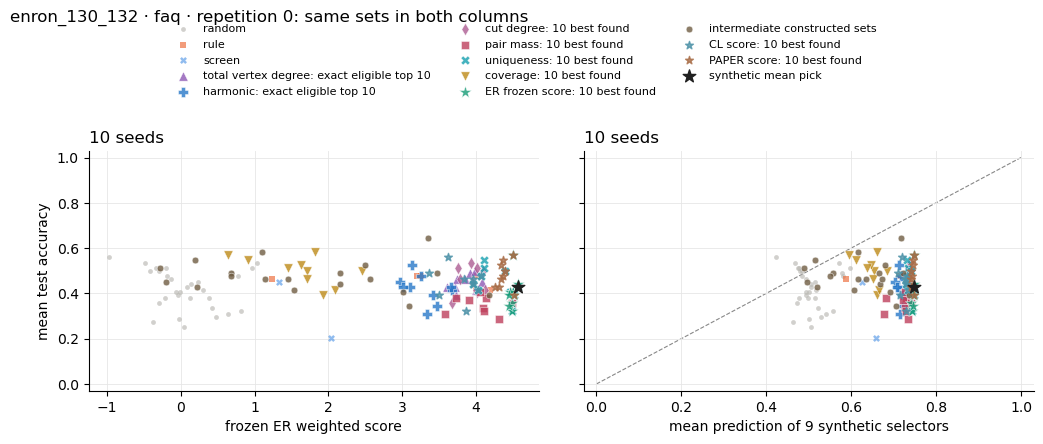

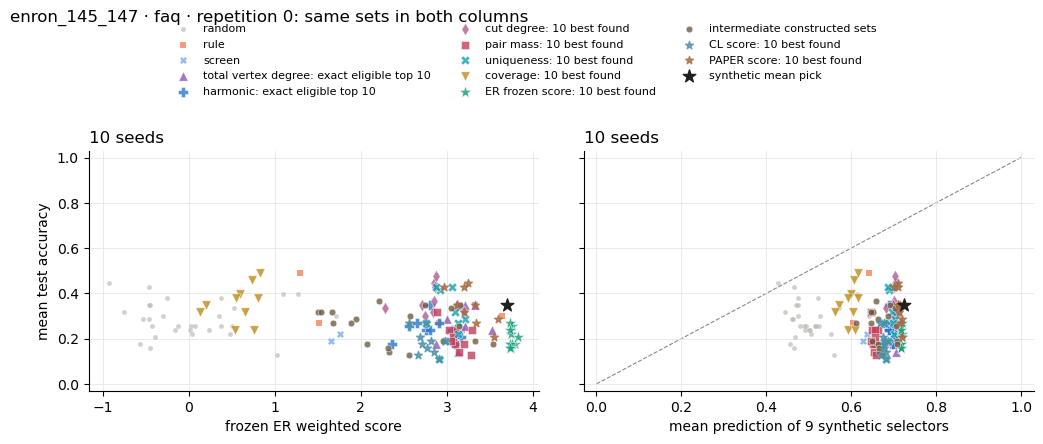

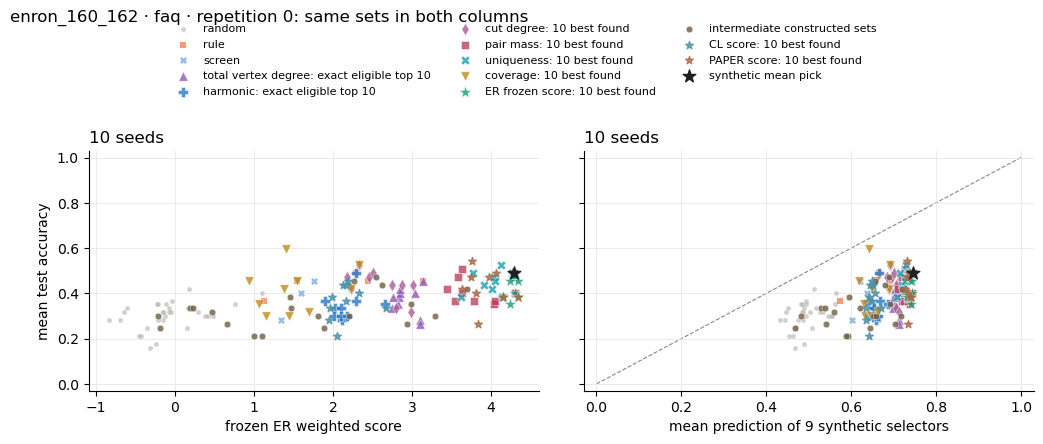

In [13]:
PLAN_WIDE_CANDIDATES = False
RUN_WIDE_COLLECTION = False
WIDE_CASES = U.PRIMARY
WIDE_VARIANTS = ("percolation", "faq", "goat_r300")

if PLAN_WIDE_CANDIDATES or RUN_WIDE_COLLECTION:
    U.run("wide", cases=WIDE_CASES, variants=WIDE_VARIANTS, replicates=3, jobs=3,
          plan_only=not RUN_WIDE_COLLECTION)

display(U.collection_status("wide"))
wide_sets, wide_members, wide_predictions = U.read("wide")
if not wide_sets.empty:
    display(U.policy_table(wide_sets, wide_members))
    display(U.transfer_table(wide_sets, wide_predictions))
    display(U.source_policy_table(wide_sets, wide_members, wide_predictions))
    for case in wide_sets.case.unique():
        for variant in wide_sets.loc[wide_sets.case == case, "variant"].unique():
            fig = U.plot_scores(wide_sets, wide_members, case, variant, replicate=0)
            if fig is not None:
                for suffix in ("png", "pdf"):
                    fig.savefig(FOLLOW_UP_FIGURES / f"{case}_{variant}_wide_rep0.{suffix}", dpi=180)
                plt.show()
else:
    print("Candidate plans can be prepared without matching; no completed wider-bank outcomes yet.")

## 10. New Enron windows and repeated test splits

The new cases are selected by their graph structure and calendar separation, not by seed-strategy performance. Weeks **100–101/102** are development diagnostics. Weeks **145–146/147** and **160–161/162** provide later test windows. Pairs sharing the same first week belong to one time window; they are not independent graph replicates. The original 130-based pairs and Wikipedia remain exploratory cases already inspected.

For native pairs, a repetition changes the test split, B's labels and solver randomness. It keeps the natural edge data fixed. Use the per-repetition table to see variation without interpreting repeated splits as independent datasets. Policy means average solver runs first, seed sets within a family second, and split repetitions last. A candidate-bank repetition is excluded until every set has its full solver-run budget, so partially collected banks are not compared. Increasing budgets, comparing different native pairs, and repeating solver runs answer different questions.

These small Enron tests have only 19–28 test vertices, so differences of a few percentage points need repeated checks. Source-selector predictions are genuine transfers, but calibration across graph sizes and budgets is not assumed.

In [14]:
display(U.inventory())
if not wide_sets.empty:
    display(U.policy_repetitions(wide_sets, wide_members))

,role,time window,n,test vertices,edge correlation
case,,,,,
enron_130_132,exploratory,original,141,28,0.765
wikipedia,exploratory,original,1382,276,0.464
enron_100_101,development,100,96,19,0.836
enron_100_102,development,100,93,19,0.721
enron_145_146,test,145,120,24,0.893
enron_145_147,test,145,104,21,0.568
enron_160_161,test,160,109,22,0.848
enron_160_162,test,160,96,19,0.655


detail                                        best of 1,000 by Chung-Lu score  best of 1,000 by degree  best of 1,000 by ER score  best of 1,000 by PAPER score  clustered (pair mass)  distinguishing  CL score: expanded bank  \
phase case          variant budget replicate                                                                                                                                                                                      
wide  enron_130_132 faq     10     0                                    0.202                    0.452                      0.202                         0.202                  0.476           0.417                    0.321   
                                   1                                    0.512                    0.488                      0.476                         0.488                  0.274           0.298                    0.274   
      enron_145_147 faq     10     0                                    0.190                    0.302                      0.222                         0.302                  0.302           0.238                    0.206   
                                   1                                    0.206                    0.302                      0.397                         0.397                  0.286           0.349                    0.175   
      enron_160_162 faq     10     0                                    0.281                    0.404                      0.456                         0.404                  0.351           0.456                    0.386   
                                   1                                    0.246                    0.474                      0.351                         0.351                  0.211           0.263                    0.333   

detail                                        ER score: expanded bank  PAPER score: expanded bank  hub-free distinguishing  random mean  spread (coverage)  synthetic selectors: mean prediction  top degree  top harmonic  
phase case          variant budget replicate                                                                                                                                                                                
wide  enron_130_132 faq     10     0                            0.429                       0.571                    0.464        0.419              0.476                                 0.429       0.417         0.476  
                                   1                            0.464                       0.393                    0.476        0.370              0.476                                 0.440       0.393         0.369  
      enron_145_147 faq     10     0                            0.206                       0.429                    0.270        0.287              0.492                                 0.349       0.349         0.270  
                                   1                            0.270                       0.286                    0.333        0.272              0.270                                 0.270       0.302         0.143  
      enron_160_162 faq     10     0                            0.456                       0.474                    0.368        0.302              0.456                                 0.491       0.456         0.491  
                                   1                            0.281                       0.404                    0.386        0.297              0.228                                 0.281       0.228         0.263

## 11. Separate controls: repeated B draws on a real topology

This optional phase keeps a real A, its test vertices and the entire A-only candidate bank fixed. Each controlled B copies an A edge indicator with probability 0.8; otherwise its edge is a Bernoulli draw at A's global density. B is then relabeled. The parameter is a **copy probability**, not a claim that the empirical edge correlation of a heterogeneous real graph equals synthetic rho.

The same seed sets are evaluated on each B, using three solver runs per B for FAQ/GOAT. We average B draws only after averaging solver runs. These are **real-topology simulations**, not additional natural Enron/Wikipedia pairs, and their results are shown separately. Their purpose is to distinguish sensitivity to edge realizations from the difficulty of the original natural correspondence.

A three-B Enron FAQ pilot is available. Enable the flag to extend to the configured five Bs and other variants/cases. No selector is trained or updated.

,case,variant,budget,replicate,runs,planned
0,enron_130_132,faq,10,0,423,423
1,enron_130_132,faq,10,1,423,423
2,enron_130_132,faq,10,2,423,423


case           variant  budget
enron_130_132  faq      10        3
Name: completed B draws, dtype: int64

,,,detail,"best of 1,000 by Chung-Lu score","best of 1,000 by degree","best of 1,000 by ER score","best of 1,000 by PAPER score",clustered (pair mass),distinguishing,CL score: expanded bank,ER score: expanded bank,PAPER score: expanded bank,hub-free distinguishing,random mean,spread (coverage),synthetic selectors: mean prediction,top degree,top harmonic
phase,case,variant,budget,,,,,,,,,,,,,,,
controls,enron_130_132,faq,10,0.683,0.639,0.683,0.683,0.579,0.639,0.607,0.631,0.607,0.639,0.644,0.599,0.631,0.611,0.635


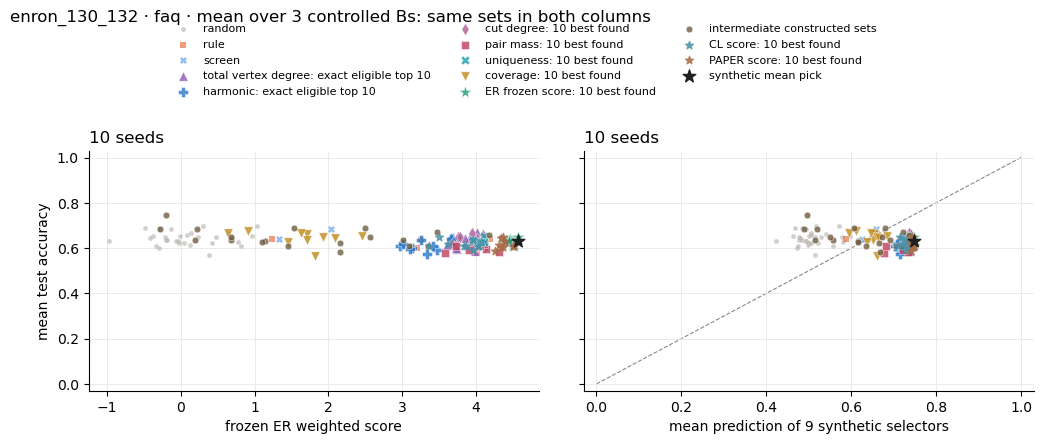

In [15]:
RUN_CONTROL_COLLECTION = False
if RUN_CONTROL_COLLECTION:
    U.run("controls", jobs=3)

display(U.collection_status("controls"))
control_sets, control_members, control_predictions = U.read("controls")
if not control_sets.empty:
    control_average, control_average_members = U.control_means(control_sets, control_members)
    display(control_average.groupby(["case", "variant", "budget"]).B_draws.min().rename("completed B draws"))
    display(U.policy_table(control_average, control_average_members))
    for case in control_average.case.unique():
        for variant in control_average.loc[control_average.case == case, "variant"].unique():
            fig = U.plot_scores(control_average, control_average_members, case, variant)
            if fig is not None:
                for suffix in ("png", "pdf"):
                    fig.savefig(FOLLOW_UP_FIGURES / f"{case}_{variant}_controlled_B_mean.{suffix}", dpi=180)
                plt.show()
else:
    print("No controlled-B outcomes yet; native-pair results remain separate.")